# 차원 축소 실습 — 빈칸 정답 및 실행 확인

| 문제 | 정답 |
|---|---|
| 1 | 차원의 저주 (Curse of Dimensionality) |
| 2 | StandardScaler |
| 3 | VarianceThreshold |
| 4 | 분산 (Variance) |
| 5 | PCA |
| 6 | explained_variance_ratio_ |
| 7 | t-SNE |
| 8 | plt.subplots |

`data.csv`가 있으면 해당 파일을 사용합니다. 없으면 scikit-learn 내장 유방암 데이터를 사용하며, 아래 저장된 실행 결과는 이 예제 데이터 기준입니다.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. 데이터 불러오기
if Path('data.csv').exists():
    df = pd.read_csv('data.csv')
    df = df.drop(['id', 'Unnamed: 32'], axis=1, errors='ignore')
    X = df.drop('diagnosis', axis=1)
    y = df['diagnosis'].map({'M': 1, 'B': 0})
    print('사용 데이터: data.csv')
else:
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer(as_frame=True)
    X = data.data
    y = 1 - data.target  # 원래 0=악성, 1=양성 → 1=악성, 0=양성
    print('사용 데이터: scikit-learn 내장 유방암 예제 (data.csv 미제공)')

print(f"원본 데이터의 형태(차원): {X.shape}")


사용 데이터: scikit-learn 내장 유방암 예제 (data.csv 미제공)
원본 데이터의 형태(차원): (569, 30)


In [2]:
# 2. 데이터 스케일링
scaler = StandardScaler()  # 2번
X_scaled = scaler.fit_transform(X)


In [3]:
# 3. 특징 선택 — 필터 기법
selector = VarianceThreshold(threshold=0.01)  # 3번
X_var = selector.fit_transform(X_scaled)
print(f"분산 기반 필터링 후 데이터 형태: {X_var.shape}")


분산 기반 필터링 후 데이터 형태: (569, 30)


표준화한 비상수 변수의 분산은 약 1이므로, 이 순서에서는 임계값 0.01로 변수가 제거되지 않습니다. 원본 실습의 순서는 유지했습니다. 또한 아래 PCA는 원본과 같이 `X_var`가 아닌 `X_scaled`를 사용합니다.

In [4]:
# 4. 특징 추출: PCA — 분산(4번)을 최대한 보존하는 축
pca = PCA(n_components=2)  # 5번
X_pca = pca.fit_transform(X_scaled)
print(f"PCA 적용 후 데이터 형태: {X_pca.shape}")

explained_variance = pca.explained_variance_ratio_  # 6번
print(f"첫 번째 주성분의 설명력: {explained_variance[0]*100:.2f}%")
print(f"두 번째 주성분의 설명력: {explained_variance[1]*100:.2f}%")
print(f"총 분산 보존율: {np.sum(explained_variance)*100:.2f}%")


PCA 적용 후 데이터 형태: (569, 2)
첫 번째 주성분의 설명력: 44.27%
두 번째 주성분의 설명력: 18.97%
총 분산 보존율: 63.24%


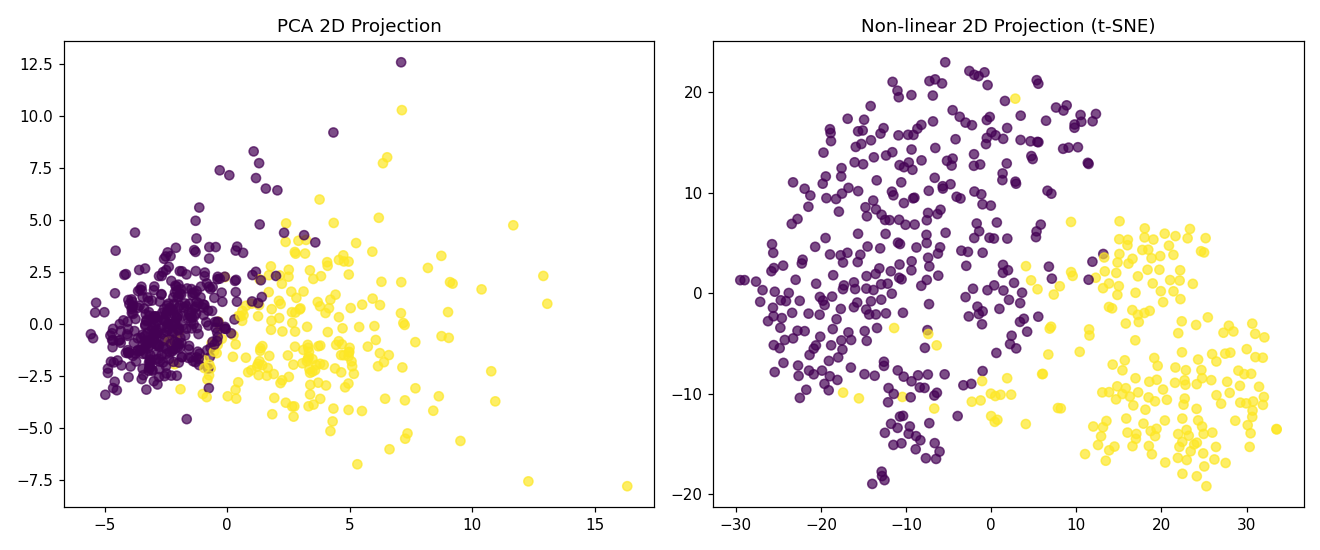

In [5]:
# 5. 비선형 차원 축소: t-SNE (7번), 시각화 목적
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # 8번
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', alpha=0.7)
axes[0].set_title('PCA 2D Projection')
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='viridis', alpha=0.7)
axes[1].set_title('Non-linear 2D Projection (t-SNE)')
plt.tight_layout()
plt.show()


색상 기준: 0=양성(B), 1=악성(M). t-SNE 결과는 가까운 이웃의 관계를 중심으로 해석하며, 군집 사이 거리·크기를 원본 데이터의 관계로 단정하지 않습니다.